<a href="https://colab.research.google.com/github/jaska12/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Menu Detector — model


In [1]:
print('Menu Detector!')

Menu Detector!


In [2]:
# --------------------------
# Import Libraries
# --------------------------
from google.colab import drive
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Define Dataset Path

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'
print('Dataset_path:', DATASET_PATH)



CUSTOM_CLASS_MAPPING = {
    "hamburger": "hamburger",
    "hot_dog": "hot_dog",
    "chocolate_cake": "dessert", # label grouping | class consolidation
    "cheesecake": "dessert",     # label grouping | class consolidation
    "kebab": "kebab",
    "pilaf": "pilaf"
}



CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

print(NUM_CLASSES)
print(CLASS_TO_IDX)


# 0 ~ 255 > 0.0 ~ 1.0    H, W, C => C, H, W | RGB = Red, Green, Blue
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # NormalizedPixel = (pixel - mean) / std
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
# Pretrained Models > ResNet / MobileNet / VGG16
# ImageNet dataset average mean and std

Dataset_path: /content/drive/MyDrive/food101_dataset
5
{'hamburger': 0, 'hot_dog': 1, 'dessert': 2, 'kebab': 3, 'pilaf': 4}


In [5]:
# ------------------------
# Custom Dataset Class
# ------------------------

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # print('images_length', len(self.images))
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)
        label = self.labels[idx]
        # print('label', label)
        try:
            image = Image.open(img_path)
            if image.mode == 'P':                # palette (PNG/GIF) rasm -> avval RGBA (ogohlantirish chiqmasligi uchun)
                image = image.convert('RGBA')
            image = image.convert('RGB') # 3 Channel
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images)) # buzuq rasm bo'lsa, keyingisini olish
        if self.transform:
            image = self.transform(image)
        return image, label

### (Qo'shimcha) Dataset'ni tekshirish
Har bir papkada nechta rasm borligini va qanday rasmlar ekanini ko'rsatadi. Begona rasmlar (odamlar, binolar...) ko'p bo'lsa, model yomon o'rganadi.

hamburger: 200 ta fayl {'.jpg': 200}
hot_dog: 200 ta fayl {'.jpg': 200}
chocolate_cake: 200 ta fayl {'.jpg': 200}
cheesecake: 200 ta fayl {'.jpg': 200}
kebab: 34 ta fayl {'.jpg': 34}
pilaf: 30 ta fayl {'.jpg': 30}


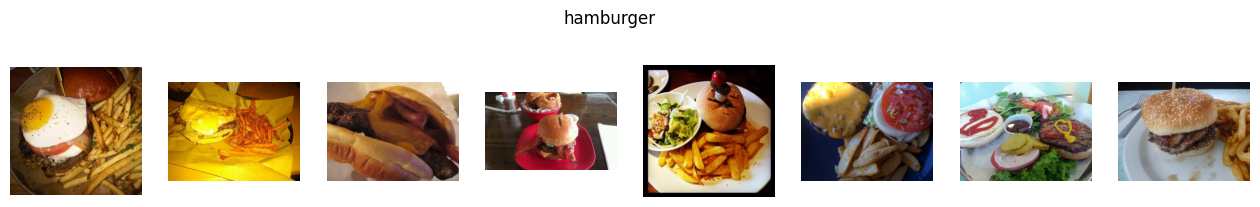

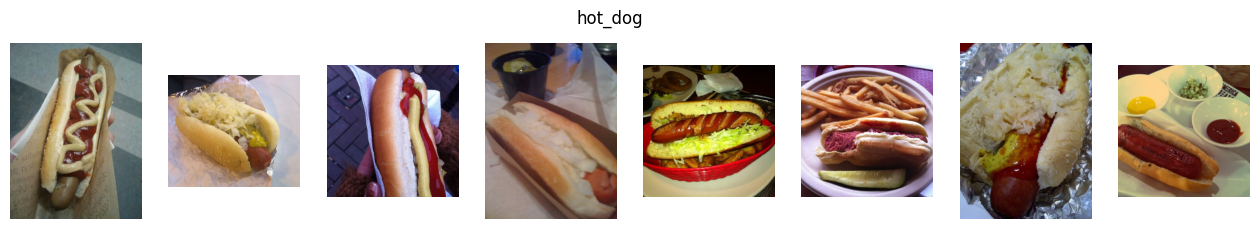

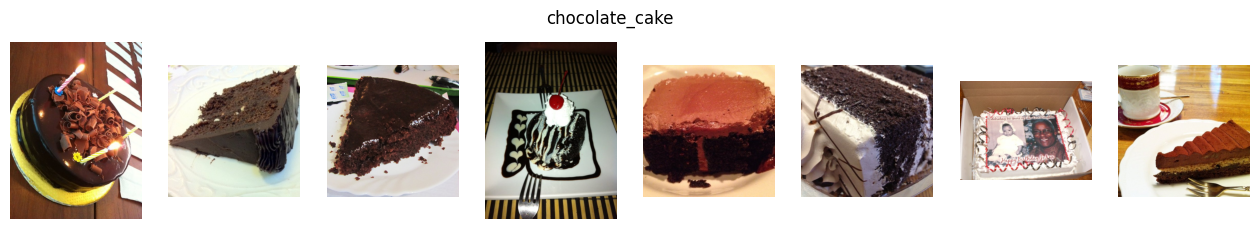

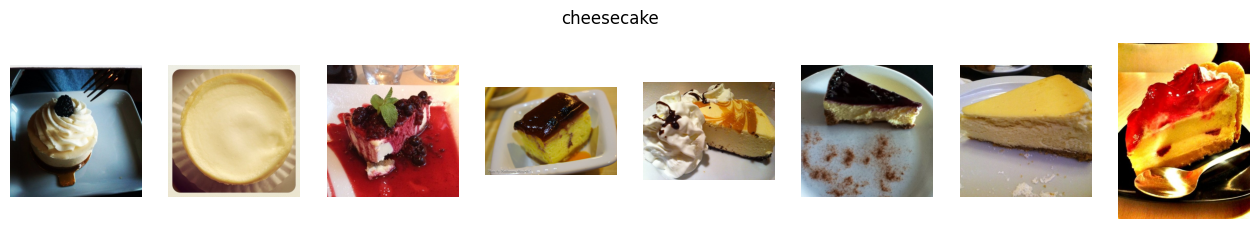

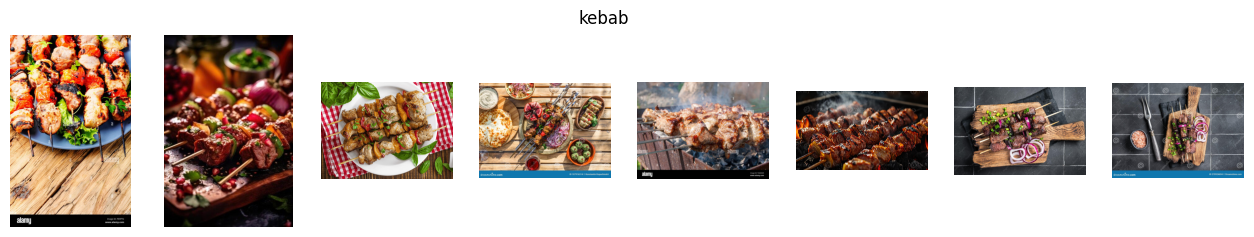

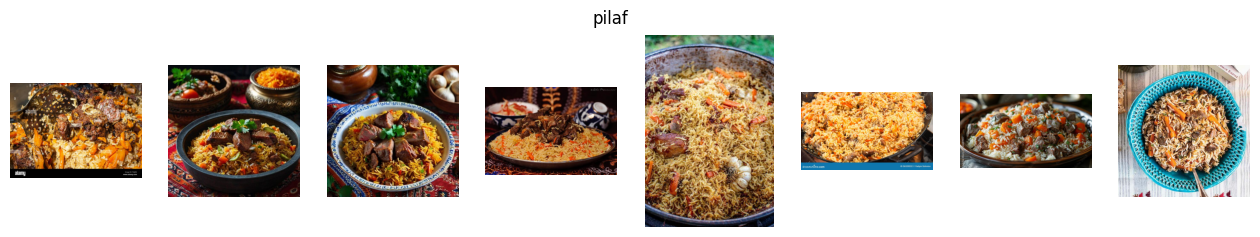

In [6]:
import random
import matplotlib.pyplot as plt

for folder in CUSTOM_CLASS_MAPPING:
    files_ = os.listdir(os.path.join(DATASET_PATH, folder))
    exts = {}
    for f in files_:
        e = os.path.splitext(f)[1].lower()
        exts[e] = exts.get(e, 0) + 1
    print(f"{folder}: {len(files_)} ta fayl {exts}")

# Har bir papkadan 8 ta tasodifiy rasm
for folder in CUSTOM_CLASS_MAPPING:
    files_ = os.listdir(os.path.join(DATASET_PATH, folder))
    sample = random.sample(files_, min(8, len(files_)))
    plt.figure(figsize=(16, 2.5))
    for i, f in enumerate(sample):
        plt.subplot(1, 8, i + 1)
        try:
            plt.imshow(Image.open(os.path.join(DATASET_PATH, folder, f)).convert('RGB'))
        except Exception:
            pass
        plt.axis('off')
    plt.suptitle(folder)
    plt.show()

In [7]:
# --------------------------
# Gather and Split Data
# --------------------------
all_images = []
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class) # /content/drive/MyDrive/food101_dataset/hamburger
    print('class_path:', class_path)
    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue
    for img in os.listdir(class_path):
        if img.endswith(('.jpg', '.jpeg', '.png')): # .txt, .docx
            full_path = os.path.join(class_path, img) # /content/drive/MyDrive/food101_dataset/hamburger/100057.jpg
            all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images)
split = int(0.8 * len(all_images))
train_data = all_images[:split] # 1000 | 800 train_data | 200 val_data
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

# print('all_images:', all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
img, lbl = dataset[0]

class_path: /content/drive/MyDrive/food101_dataset/hamburger
class_path: /content/drive/MyDrive/food101_dataset/hot_dog
class_path: /content/drive/MyDrive/food101_dataset/chocolate_cake
class_path: /content/drive/MyDrive/food101_dataset/cheesecake
class_path: /content/drive/MyDrive/food101_dataset/kebab
class_path: /content/drive/MyDrive/food101_dataset/pilaf
691


In [8]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [9]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2) #thread | parallel loading for speed
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [10]:
# pretrained model
model = mobilenet_v2(weights="IMAGENET1K_V1") # pretrained model | ligthweight | CNN | 1000 class | million
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES) # fine-tuning | backbone | model layer freeze

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 167MB/s]


In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)
model = model.to(device)

device cuda


In [12]:
criterion = nn.CrossEntropyLoss() # Loss Function | '70%' burger, '30%' pilaf
optimizer = optim.Adam(model.parameters(), lr=0.001) # weight
torch.backends.cudnn.benchmark = True # Benchmark Setting | Trick | 10%-20%

In [13]:
NUM_EPOCHS = 10
best_accuracy = 0.0

for epoch in range(NUM_EPOCHS):
    model.train() # train mode
    running_loss = 0.0 # 70% | 30%Loss | 100%
    for images, labels in train_loader: # Forward and Backward(Backpropagation)
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad() # zero the gradient
        outputs = model(images) # Forward Pass | Dog | 5 Classes
        loss = criterion(outputs, labels) # Calculate Loss
        loss.backward()
        optimizer.step() # Adam optimizer
        running_loss += loss.item() # Track Loss

    # Validation
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] Loss: {running_loss/len(train_loader):.4f}, Val Accuracy: {val_acc:.2f}%")

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(model.state_dict(), '/content/menu_detector.pth')
        print("Saved new best model!")

Epoch [1/10] Loss: 0.6671, Val Accuracy: 75.72%
Saved new best model!
Epoch [2/10] Loss: 0.2799, Val Accuracy: 87.28%
Saved new best model!
Epoch [3/10] Loss: 0.1221, Val Accuracy: 89.02%
Saved new best model!
Epoch [4/10] Loss: 0.1079, Val Accuracy: 89.60%
Saved new best model!
Epoch [5/10] Loss: 0.1349, Val Accuracy: 82.66%
Epoch [6/10] Loss: 0.1395, Val Accuracy: 84.97%
Epoch [7/10] Loss: 0.1280, Val Accuracy: 82.08%
Epoch [8/10] Loss: 0.1252, Val Accuracy: 86.71%
Epoch [9/10] Loss: 0.0722, Val Accuracy: 83.82%
Epoch [10/10] Loss: 0.0717, Val Accuracy: 80.92%


# menu_detector model usage
O'qitilgan `menu_detector.pth` modelini yuklab, yangi rasm bo'yicha bashorat qilish.

device: cuda
Upload one or more images of hamburger or hot dog:


Saving pilof.webp to pilof.webp


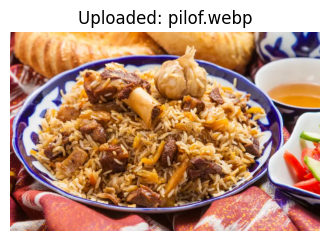

Prediction:
  ✅ pilaf: 99.43%
  ✅ hot_dog: 0.46%
  ✅ kebab: 0.08%
  ✅ dessert: 0.02%


In [14]:
# -----------------------------------------
# Required Imports
# -----------------------------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# -----------------------------------------
# Define Semantic Classes
# -----------------------------------------
CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']  # Must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# -----------------------------------------
# Transform for Uploaded Images (no augmentations!)
# -----------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# -----------------------------------------
# Load Model
# -----------------------------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# -----------------------------------------
# Upload & Predict
# -----------------------------------------
print("Upload one or more images of hamburger or hot dog:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  ✅ {label}: {confidence:.2f}%")